In [1]:
from ccvtools import rawio
import imageio.v2 as iio
import numpy as np
from tqdm import tqdm

%matplotlib ipympl
import matplotlib.pyplot as plt 

In [2]:
files = [
    "H:/yamlsaving/aptina1.ccv",
    # "G:/yamlsaving/pylon4.ccv"
]

In [3]:
framerate = 100

In [4]:
readers = [iio.get_reader(file) for file in files]
print("Number of frames: ", [len(r) for r in readers])

Number of frames:  [183]


In [5]:
# Read all timestamps from video files for further analysis
timestamps_all = []
fr_idxs_all = []
for i_c, r in enumerate(readers):
    timestamps = []
    fr_idxs = []
    for i_f in range(len(r)):
        md = readers[i_c].get_meta_data(i_f)
        timestamps.append(md["timestamp"])
        fr_idxs.append(md["index"])
    timestamps_all.append(np.array(timestamps))
    fr_idxs_all.append(np.array(fr_idxs))

==== Cam 0 ====
Maximum step in frame idx:  3252707339
Maximum and minimum local fps:  -4.629609581577464e-298 4.629609581577464e-298
Number of frames with local fps < 75/s 158


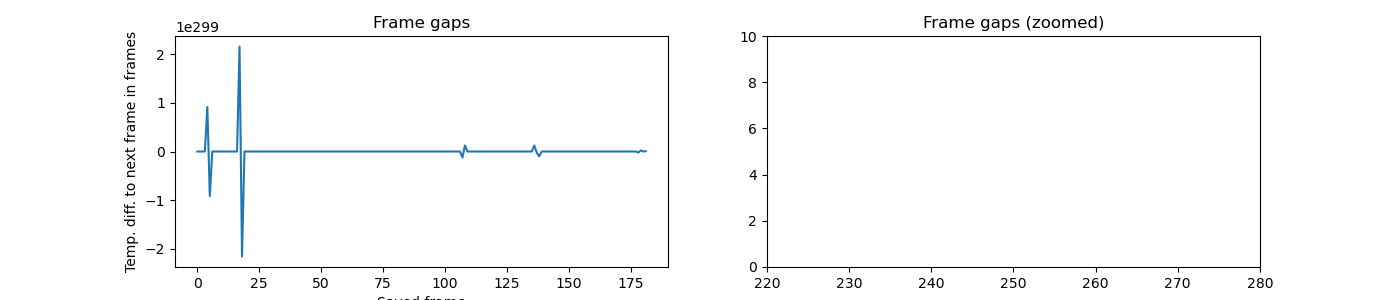

In [6]:
# Plot gaps between frames based on camera times
fig, axs = plt.subplots(1,2, figsize=(14,3))
for i_id, (ids, ts) in enumerate(zip(fr_idxs_all, timestamps_all)):
    print(f"==== Cam {i_id} ====")
    print("Maximum step in frame idx: ", np.max(np.diff(ids)))
    print("Maximum and minimum local fps: ", 1/np.min(np.diff(ts)), 1/np.max(np.diff(ts)))
    print(f"Number of frames with local fps < {int(0.75*framerate)}/s", np.sum(1/np.diff(ts) < 0.75*framerate))
    axs[0].plot(np.diff(ts)*framerate)
    axs[0].set_title("Frame gaps")
    axs[0].set_xlabel("Saved frame")
    axs[0].set_ylabel("Temp. diff. to next frame in frames")
    axs[1].plot(np.diff(ts)*framerate)
    axs[1].set_xlim((220,280))
    axs[1].set_ylim((0,10))
    axs[1].set_title("Frame gaps (zoomed)")
    axs[0].set_xlabel("Saved frame")

In [7]:
# Print first 10 saved frame idxs and cam times
for i_cam in range(len(files)):
    print("Cam ", i_cam)
    timestamps = []
    for i in range(10):
        md = readers[i_cam].get_meta_data(i)
        print(md)
        timestamps.append(md["timestamp"])
    timestamps = np.array(timestamps)
    print(np.diff(timestamps)/(1/framerate))

Cam  0
{'index': 1882964733, 'timestamp': 8.288893633896982e+72}
{'index': 1508312516, 'timestamp': -137555147.01067647}
{'index': 2565242277, 'timestamp': -9.790507577296203e+161}
{'index': 2567332259, 'timestamp': 3.291268225243748e+258}
{'index': 3665220032, 'timestamp': 9.721140528087942e+200}
{'index': 456606171, 'timestamp': 9.151080773589803e+296}
{'index': 1572337193, 'timestamp': 1.727084858924571e-12}
{'index': 3800639078, 'timestamp': 9.912736774942824e+84}
{'index': 627712669, 'timestamp': 3.539362976990551e+123}
{'index': 2805646018, 'timestamp': 57480046.936514944}
[-8.28889363e+074 -9.79050758e+163  3.29126823e+260 -3.29126823e+260
  9.15108077e+298 -9.15108077e+298  9.91273677e+086  3.53936298e+125
 -3.53936298e+125]


In [8]:
print(r.get_data(5).shape)

(480, 752)


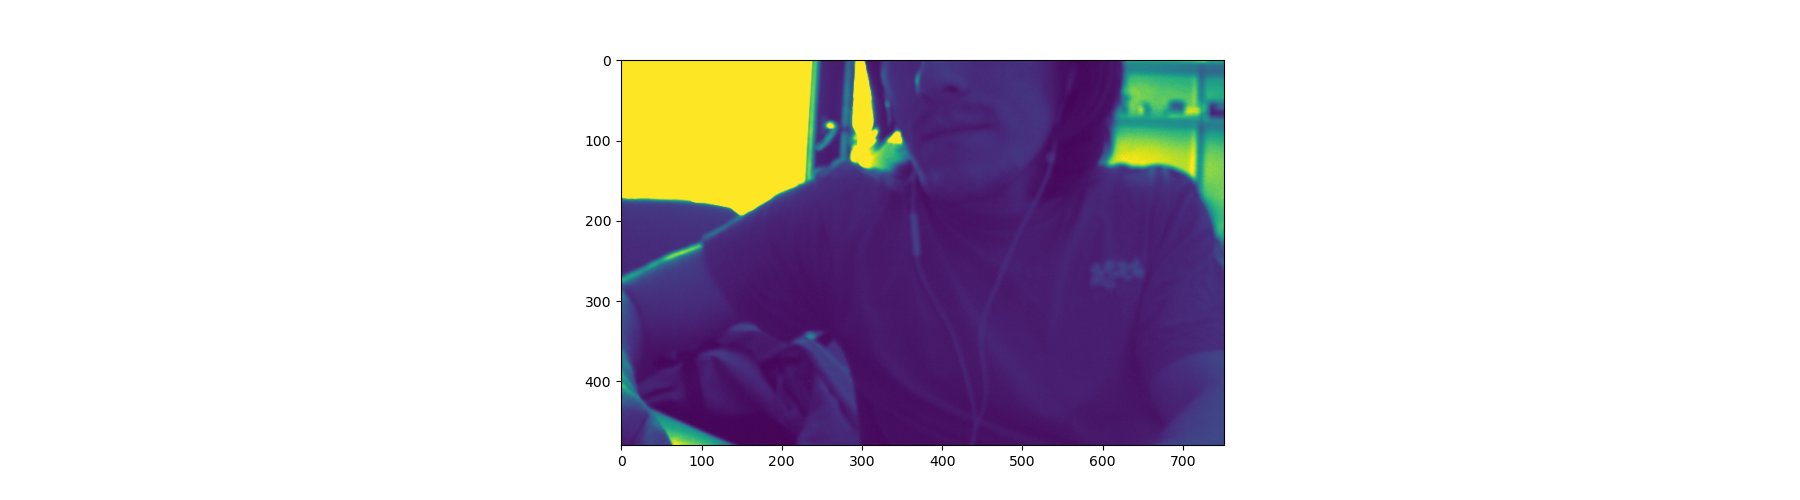

In [9]:
# Plot single frame from each cam
fig, axs = plt.subplots(1,len(files), figsize=(18,5), squeeze=False)
for ax,r in zip(axs[0],readers):
    ax.imshow(r.get_data(100))

In [10]:
# Print local frame rate
1/np.diff(timestamps)

array([-1.20643363e-073, -1.02139750e-162,  3.03834246e-259,
       -3.03834246e-259,  1.09276710e-297, -1.09276710e-297,
        1.00880314e-085,  2.82536718e-124, -2.82536718e-124])